## Tahap 1 — Business Understanding

**Masalah bisnis:** Identifikasi bunga secara manual dapat memakan waktu dan terjadi salah klasifikasi.  
**Tujuan:** Membangun klasifikasi 3 jenis Iris: setosa, versicolor, dan virginica menggunakan ukuran sepal dan petal.  
**Kriteria teknis contoh:** mengukur akurasi dan F1-score pada data uji, bukan menjanjikan akurasi tertentu.  
**Batasan:** Dataset hanya 150 observasi; hasil adalah prototipe untuk pembelajaran.

In [ ]:
%pip install -q "scikit-learn==1.8.0" "joblib>=1.4,<2"

## Tahap 2 — Data Understanding

Lihat jumlah baris, daftar fitur, kelas target, dan apakah ada nilai kosong.

In [ ]:
import pandas as pd
import sklearn
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame.copy()

print("Versi scikit-learn:", sklearn.__version__)
print("Ukuran dataset (baris, kolom):", df.shape)
print("Nama 4 fitur:", iris.feature_names)
print("Jenis bunga:", list(iris.target_names))
print("Jumlah data kosong:", int(df.isna().sum().sum()))
print("Jumlah tiap kelas:")
print(df["target"].map(dict(enumerate(iris.target_names))).value_counts())
display(df.head())

Versi scikit-learn: 1.8.0
Ukuran dataset (baris, kolom): (150, 5)
Nama 4 fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Jenis bunga: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Jumlah data kosong: 0
Jumlah tiap kelas:
target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## Tahap 3 — Data Preparation

Dataset Iris bawaan sudah lengkap. Pisahkan fitur (`X`) dan label (`y`), lalu bagi **80% data latih** dan **20% data uji** secara stratifikasi. Standardisasi akan dipelajari **hanya pada data latih** melalui `Pipeline` untuk menghindari *data leakage*.

In [ ]:
from sklearn.model_selection import train_test_split

X = df[iris.feature_names]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Data latih:", len(X_train), "baris")
print("Data uji:", len(X_test), "baris")

Data latih: 120 baris
Data uji: 30 baris


## Tahap 4 — Modeling

Gunakan `KNeighborsClassifier` dengan `k=5` dan `StandardScaler` dalam satu pipeline.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])
model.fit(X_train, y_train)
print("Model KNN berhasil dilatih!")

Model KNN berhasil dilatih!


## Tahap 5 — Evaluation

Evaluasi hanya dengan **data uji** yang tidak digunakan pada pelatihan. Perhatikan jumlah prediksi benar/salah, akurasi, F1-score, dan confusion matrix.

Akurasi: 93.33%
F1-score (macro): 0.933

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



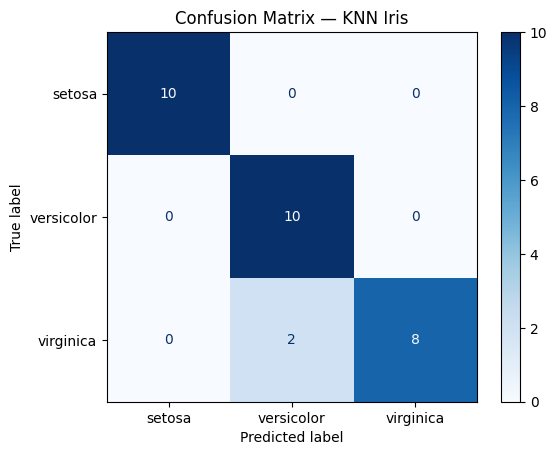

In [ ]:
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

prediksi = model.predict(X_test)
print(f"Akurasi: {accuracy_score(y_test, prediksi):.2%}")
print(f"F1-score (macro): {f1_score(y_test, prediksi, average='macro'):.3f}")
print("\nClassification report:")
print(classification_report(y_test, prediksi, target_names=iris.target_names))

ConfusionMatrixDisplay.from_predictions(
    y_test, prediksi, display_labels=iris.target_names, cmap="Blues"
)
plt.title("Confusion Matrix — KNN Iris")
plt.show()

## Tahap 6 — Deployment: Simpan model dan unduh

Simpan seluruh pipeline (standarisasi dan KNN), nama fitur, serta nama kelas ke dalam **satu file** agar preprocessing pada website sama seperti saat pelatihan.

In [ ]:
import joblib

nama_file = "model_iris_knn.joblib"
joblib.dump({
    "pipeline": model,
    "feature_names": list(iris.feature_names),
    "target_names": list(iris.target_names),
    "sklearn_version": sklearn.__version__,
}, nama_file)
print("Model tersimpan sebagai:", nama_file)

from google.colab import files
files.download(nama_file)

Model tersimpan sebagai: model_iris_knn.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Contoh interpretasi dan kaitan dengan bisnis

- **Input aplikasi:** 4 ukuran bunga dalam sentimeter.
- **Output aplikasi:** Setosa, Versicolor, atau Virginica.
- **Manfaat ilustratif:** Staf toko tanaman dapat memperoleh rekomendasi klasifikasi sebelum memberi label tanaman.
- **Keterbatasan:** Data kecil dan terbatas pada spesies serta kondisi dataset; belum divalidasi untuk penggunaan komersial nyata.

Langkah berikutnya: simpan `model_iris_knn.joblib` di folder yang sama dengan `app.py`, lalu jalankan Streamlit sesuai `PANDUAN.md`.